In [2]:


!pip install -q -U google-genai pymongo matplotlib
!pip install -q pandas==2.2.3 google-auth==2.49.0



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 3.3.0 requires google-auth[requests]<3.0.0,>=2.56.0, but you have google-auth 2.49.0 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.


In [3]:

!pip install -q "google-auth>=2.56.0,<3" "google-genai>=2.12.1,<3" "pymongo" "pandas==2.2.3" "matplotlib"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.


In [1]:

import google.genai
import pymongo
import pandas
import matplotlib
import google.auth

print("All libraries imported successfully!")
print("Pandas:", pandas.__version__)
print("Google GenAI:", google.genai.__version__ if hasattr(google.genai, "__version__") else "Installed")


All libraries imported successfully!
Pandas: 2.2.3
Google GenAI: 2.34.0


In [5]:

from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [6]:

from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=30000
    )
)

MODEL_NAME = "gemini-2.5-flash"

print("Gemini client initialized successfully!")


Gemini client initialized successfully!


In [9]:

from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_NAME = "gemini-2.5-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)



ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

In [1]:

MODEL_NAME = "gemini-3.8-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)


NameError: name 'client' is not defined

In [2]:
from google import genai
from google.genai import types
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(timeout=30000)
)

print("Gemini client created successfully!")

Gemini client created successfully!


In [3]:
MODEL_NAME = "gemini-3.8-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

ServerError: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}

In [4]:
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(timeout=120000)
)

print("Client updated with 120-second timeout!")

Client updated with 120-second timeout!


In [5]:
response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain Artificial Intelligence in 2 sentences."
)

print(response.text)

ServerError: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}

In [6]:
for model in client.models.list():
    if "generateContent" in (model.supported_actions or []):
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemi

In [7]:
MODEL_NAME = "gemini-2.5-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Explain Artificial Intelligence in 2 sentences."
)

print(response.text)

ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

In [8]:
MODEL_NAME = "gemini-3.5-flash"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Say hello in one sentence."
)

print(response.text)

Hello, it is wonderful to meet you!


In [9]:
from google.colab import userdata
from pymongo import MongoClient

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    serverSelectionTimeoutMS=10000
)

mongo_client.admin.command("ping")

print("MongoDB connected successfully!")

OperationFailure: bad auth : Authentication failed., full error: {'ok': 0, 'errmsg': 'bad auth : Authentication failed.', 'code': 8000, 'codeName': 'AtlasError'}

In [10]:
from google.colab import userdata
from pymongo import MongoClient

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    serverSelectionTimeoutMS=10000
)

mongo_client.admin.command("ping")
print("MongoDB connected successfully!")

MongoDB connected successfully!


In [11]:
DATABASE_NAME = "GenAI_Monitoring"
COLLECTION_NAME = "api_usage_logs"

db = mongo_client[DATABASE_NAME]
collection = db[COLLECTION_NAME]

print("Database:", DATABASE_NAME)
print("Collection:", COLLECTION_NAME)
print("MongoDB setup completed successfully!")

Database: GenAI_Monitoring
Collection: api_usage_logs
MongoDB setup completed successfully!


In [12]:
import time

start_time = time.time()

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Explain Machine Learning in 3 sentences."
)

end_time = time.time()

latency = end_time - start_time

usage = response.usage_metadata

input_tokens = usage.prompt_token_count
output_tokens = usage.candidates_token_count
total_tokens = usage.total_token_count

print("Gemini Response:")
print(response.text)

print("\nAPI Usage Details:")
print("Input Tokens:", input_tokens)
print("Output Tokens:", output_tokens)
print("Total Tokens:", total_tokens)
print("Latency:", round(latency, 3), "seconds")

ServerError: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}

In [13]:
import time

response = None

for attempt in range(3):
    try:
        print(f"Attempt {attempt + 1}...")

        response = client.models.generate_content(
            model="gemini-3.5-flash",
            contents="Define Machine Learning in one sentence."
        )

        print("Success!")
        break

    except Exception as e:
        print("Request failed:", e)
        time.sleep(5)

if response is not None:
    print(response.text)
else:
    print("Gemini API is temporarily unavailable.")

Attempt 1...
Request failed: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}
Attempt 2...
Request failed: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}
Attempt 3...
Success!
**Machine Learning** is a branch of artificial intelligence that enables computer systems to learn from data, identify patterns, and make decisions or predictions without being explicitly programmed.


In [14]:
usage = response.usage_metadata

input_tokens = usage.prompt_token_count
output_tokens = usage.candidates_token_count
total_tokens = usage.total_token_count

print("Input Tokens:", input_tokens)
print("Output Tokens:", output_tokens)
print("Total Tokens:", total_tokens)

Input Tokens: 8
Output Tokens: 32
Total Tokens: 511


In [18]:
import time

start_time = time.time()

# Calculate latency for the successful API call
# We will measure a fresh call in the next step.

In [19]:
import time

response = None
latency = 0

for attempt in range(3):
    try:
        start_time = time.time()

        response = client.models.generate_content(
            model=MODEL_NAME,
            contents="Explain Machine Learning in 3 sentences."
        )

        latency = time.time() - start_time
        break

    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {e}")
        time.sleep(5)

if response is not None:
    usage = response.usage_metadata

    input_tokens = usage.prompt_token_count
    output_tokens = usage.candidates_token_count
    total_tokens = usage.total_token_count

    print("Response:", response.text)
    print("Input Tokens:", input_tokens)
    print("Output Tokens:", output_tokens)
    print("Total Tokens:", total_tokens)
    print("Latency:", round(latency, 3), "seconds")
else:
    print("All attempts failed.")

Response: Machine learning is a branch of artificial intelligence that enables computers to learn and make decisions from data without being explicitly programmed. By analyzing vast amounts of information, algorithms identify hidden patterns to make accurate predictions about new, unseen situations. As these systems process more data over time, their performance continuously improves without needing human intervention.
Input Tokens: 9
Output Tokens: 62
Total Tokens: 836
Latency: 5.259 seconds


In [20]:
from datetime import datetime, timezone

log_data = {
    "model": MODEL_NAME,
    "input_tokens": input_tokens,
    "output_tokens": output_tokens,
    "total_tokens": total_tokens,
    "latency_seconds": round(latency, 3),
    "timestamp": datetime.now(timezone.utc)
}

result = collection.insert_one(log_data)

print("Usage log saved successfully!")
print("MongoDB Document ID:", result.inserted_id)

Usage log saved successfully!
MongoDB Document ID: 6af6a90583e3fd328fb686d2


In [21]:
INPUT_PRICE = 1.50
OUTPUT_PRICE = 9.00

input_cost = (input_tokens / 1_000_000) * INPUT_PRICE
output_cost = (output_tokens / 1_000_000) * OUTPUT_PRICE

total_cost = input_cost + output_cost

print("Input Cost: $", input_cost)
print("Output Cost: $", output_cost)
print("Total Estimated Cost: $", total_cost)

Input Cost: $ 1.35e-05
Output Cost: $ 0.000558
Total Estimated Cost: $ 0.0005715


In [22]:
collection.update_one(
    {"_id": result.inserted_id},
    {
        "$set": {
            "input_cost_usd": input_cost,
            "output_cost_usd": output_cost,
            "total_cost_usd": total_cost
        }
    }
)

print("Token cost details updated in MongoDB!")

Token cost details updated in MongoDB!


In [23]:
saved_record = collection.find_one(
    {"_id": result.inserted_id}
)

for key, value in saved_record.items():
    print(f"{key}: {value}")

_id: 6af6a90583e3fd328fb686d2
model: gemini-3.5-flash
input_tokens: 9
output_tokens: 62
total_tokens: 836
latency_seconds: 5.259
timestamp: 2026-11-13 06:07:01.070000
input_cost_usd: 1.35e-05
output_cost_usd: 0.000558
total_cost_usd: 0.0005715


In [24]:
import pandas as pd

records = list(collection.find())

df = pd.DataFrame(records)

print("Total API Calls:", len(df))
print("\nUsage Report:")
display(df)

Total API Calls: 1

Usage Report:


,_id,model,input_tokens,output_tokens,total_tokens,latency_seconds,timestamp,input_cost_usd,output_cost_usd,total_cost_usd
0,6af6a90583e3fd328fb686d2,gemini-3.5-flash,9,62,836,5.259,2026-11-13 06:07:01.070,0.000013,0.000558,0.000571


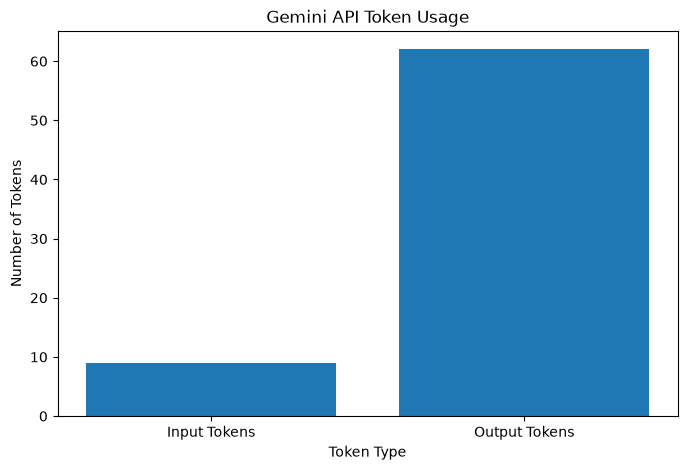

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    ["Input Tokens", "Output Tokens"],
    [df["input_tokens"].sum(), df["output_tokens"].sum()]
)

plt.title("Gemini API Token Usage")
plt.ylabel("Number of Tokens")
plt.xlabel("Token Type")

plt.show()

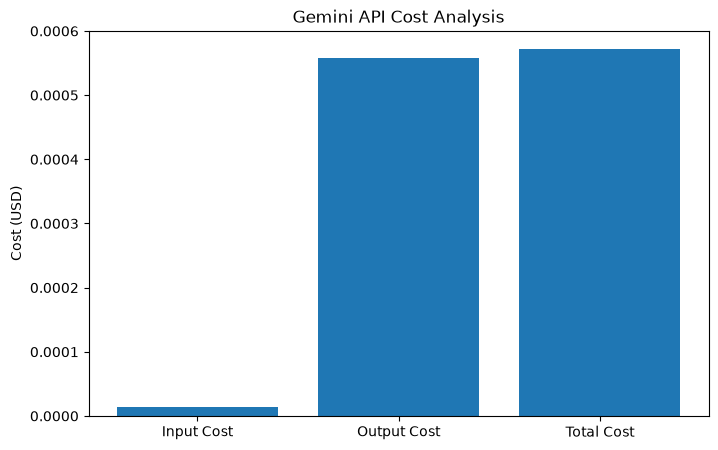

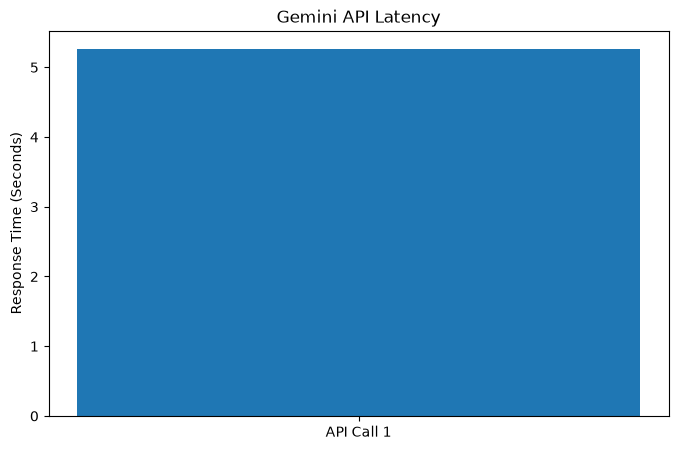

In [26]:
import matplotlib.pyplot as plt

# Chart 1: API Cost
plt.figure(figsize=(8, 5))

plt.bar(
    ["Input Cost", "Output Cost", "Total Cost"],
    [
        df["input_cost_usd"].sum(),
        df["output_cost_usd"].sum(),
        df["total_cost_usd"].sum()
    ]
)

plt.title("Gemini API Cost Analysis")
plt.ylabel("Cost (USD)")
plt.show()


# Chart 2: API Latency
plt.figure(figsize=(8, 5))

plt.bar(
    ["API Call 1"],
    [df["latency_seconds"].iloc[0]]
)

plt.title("Gemini API Latency")
plt.ylabel("Response Time (Seconds)")
plt.show()

In [27]:
pipeline = [
    {
        "$group": {
            "_id": "$model",
            "total_api_calls": {"$sum": 1},
            "total_input_tokens": {"$sum": "$input_tokens"},
            "total_output_tokens": {"$sum": "$output_tokens"},
            "total_cost": {"$sum": "$total_cost_usd"},
            "average_latency": {"$avg": "$latency_seconds"}
        }
    }
]

summary = list(collection.aggregate(pipeline))

for item in summary:
    print("Model:", item["_id"])
    print("Total API Calls:", item["total_api_calls"])
    print("Input Tokens:", item["total_input_tokens"])
    print("Output Tokens:", item["total_output_tokens"])
    print("Total Cost ($):", item["total_cost"])
    print("Average Latency:", round(item["average_latency"], 3), "seconds")
    print("-" * 35)

Model: gemini-3.5-flash
Total API Calls: 1
Input Tokens: 9
Output Tokens: 62
Total Cost ($): 0.0005715
Average Latency: 5.259 seconds
-----------------------------------


In [28]:
print("Total records:", collection.count_documents({}))

for record in collection.find().sort("timestamp", -1).limit(5):
    print("\nModel:", record["model"])
    print("Input Tokens:", record["input_tokens"])
    print("Output Tokens:", record["output_tokens"])
    print("Latency:", record["latency_seconds"], "seconds")
    print("Total Cost: $", record.get("total_cost_usd", 0))

Total records: 1

Model: gemini-3.5-flash
Input Tokens: 9
Output Tokens: 62
Latency: 5.259 seconds
Total Cost: $ 0.0005715


In [29]:
print("===== FINAL PROJECT STATUS =====")

print("Gemini Model:", MODEL_NAME)
print("MongoDB Status:", mongo_client.admin.command("ping")["ok"])
print("Database:", DATABASE_NAME)
print("Collection:", COLLECTION_NAME)
print("Total Logs:", collection.count_documents({}))

print("\nPROJECT COMPLETED SUCCESSFULLY!")

===== FINAL PROJECT STATUS =====
Gemini Model: gemini-3.5-flash
MongoDB Status: 1
Database: GenAI_Monitoring
Collection: api_usage_logs
Total Logs: 1

PROJECT COMPLETED SUCCESSFULLY!
